# ChurnGuard: modelling notebook
This notebook walks through the modelling decisions behind ChurnGuard: **model comparison, imbalance handling, calibration, the cost-based threshold, test evaluation, SHAP explanations and a per-customer value view.** It imports the same functions as `train.py` (`src/data.py`, `src/modeling.py`, `src/business.py`, `src/explainability.py`), so nothing here is a separate implementation.

**Source of truth.** The numbers in the README, the reports and the app all come from the saved run in `models/metadata.json` and `reports/`. This notebook reads those files, and recomputes what it cheaply can (test metrics, SHAP, scoring). The expensive 5-fold comparison is not re-run by default (flag below), because gradient boosting can differ slightly between machines and library builds, which would put different numbers in the notebook than in the README.

**Data.** If `data/Telco_customer_churn.xlsx` exists the notebook uses it. If not, it falls back to `data/sample_telco.csv` (300 stratified rows) so every cell still runs; the cells that need the full data say so.

In [1]:
import json, warnings
from pathlib import Path
import joblib, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
warnings.filterwarnings("ignore")

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
import sys; sys.path.insert(0, str(ROOT))

from src import business
from src.data import FEATURES, NUMERIC, CATEGORICAL, EXCLUDED, DATA_PATH, load_xy, validate_input
from src.modeling import SEED, build_pipeline, make_preprocessor, metrics_at
from src.explainability import ChurnExplainer

REPORTS, MODELS = ROOT / "reports", ROOT / "models"
meta = json.loads((MODELS / "metadata.json").read_text())
RERUN_CV = False   # set True to recompute the 5-fold comparison (about 1 minute; results can differ slightly by machine)
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
print("Selected model:", meta["model"], "| calibration:", meta["calibration"], "| threshold:", meta["threshold"])

Selected model: XGBoost (scale_pos_weight) | calibration: isotonic | threshold: 0.32


## 1. Data, target and leakage columns
Target: `Churn Value` (1 = churned, 26.5% of customers). The columns below are **never** model inputs: identifiers, the target itself, and fields that are derived from or recorded after the outcome (`Churn Score`, `Churn Reason`, `CLTV`).

In [2]:
FULL = DATA_PATH.exists()
if FULL:
    X, y, raw = load_xy()
    print(f"Full dataset: {X.shape[0]:,} customers, churn rate {y.mean():.1%}")
else:
    s = pd.read_csv(ROOT / "data" / "sample_telco.csv")
    X, y = s[FEATURES], s["Churn Value"].astype(int)
    print(f"Excel file not found: using the 300-row sample ({y.mean():.1%} churn). Full-data cells will be skipped.")
print(f"\n{len(FEATURES)} model inputs: {len(NUMERIC)} numeric + {len(CATEGORICAL)} categorical")
print("Excluded columns:", ", ".join(EXCLUDED))

Full dataset: 7,043 customers, churn rate 26.5%

19 model inputs: 3 numeric + 16 categorical
Excluded columns: CustomerID, Churn Label, Churn Value, Churn Score, Churn Reason, CLTV, Count, Country, State, City, Zip Code, Lat Long, Latitude, Longitude


## 2. Model comparison (5-fold stratified CV on the training split, PR-AUC)
Six candidates plus a dummy baseline are compared on **out-of-fold** predictions from the 80% training split only; the 20% test split is not touched until section 6. PR-AUC (average precision) is the main metric because only 26.5% of customers churn, so accuracy and ROC-AUC can look good while the churn class is ranked poorly. The dummy baseline scores about the churn rate (0.265), which is the floor.

In [3]:
cmp = pd.read_csv(REPORTS / "model_comparison.csv")
display(cmp.round(4))
fig, ax = plt.subplots(figsize=(8, 3.6))
order = cmp.sort_values("PR-AUC")
ax.barh(order["Model"], order["PR-AUC"], color=["#bbb" if "Dummy" in m else "#3b6fb6" for m in order["Model"]])
for i, v in enumerate(order["PR-AUC"]): ax.text(v + 0.005, i, f"{v:.4f}", va="center", fontsize=9)
ax.set_xlabel("PR-AUC (out-of-fold, training split)"); ax.set_xlim(0, 0.8); ax.set_title("Model comparison")
plt.tight_layout(); plt.show()

,Model,PR-AUC,ROC-AUC,Precision,Recall,F1,TN,FP,FN,TP
0,XGBoost (scale_pos_weight),0.6859,0.8626,0.5369,0.8167,0.6479,3086,1053,274,1221
1,XGBoost (SMOTE),0.6827,0.8625,0.6042,0.7003,0.6487,3453,686,448,1047
2,Random Forest (class weights),0.6793,0.8622,0.5584,0.7773,0.6499,3220,919,333,1162
3,Logistic Regression (class weights),0.6760,0.8585,0.5295,0.8094,0.6402,3064,1075,285,1210
4,Logistic Regression (SMOTE),0.6754,0.8578,0.5417,0.7993,0.6458,3128,1011,300,1195
5,Dummy (prior),0.2653,0.4999,0.0000,0.0000,0.0000,4139,0,1495,0


**Reading the table.** The top four models are within about 0.015 PR-AUC of each other, so XGBoost with class weights is a *narrow* win, not a decisive one. The logistic regression is a strong, simple baseline: the signal in this dataset is mostly contract type, tenure and services, which linear models capture well. Confusion matrices at the 0.50 cut-off (TN/FP/FN/TP columns above) show the trade-off: class-weighted models catch more churners (recall about 0.8) at lower precision (about 0.54), while the SMOTE variants sit in between.

In [4]:
if RERUN_CV and FULL:
    from sklearn.model_selection import train_test_split
    from src.modeling import compare_models
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
    fresh, _, _ = compare_models(Xtr, ytr)
    display(fresh.round(4))
else:
    print("Skipped (RERUN_CV = False). The table above is the saved run used everywhere else.")

Skipped (RERUN_CV = False). The table above is the saved run used everywhere else.


## 3. Imbalance handling: class weights vs SMOTE
Two approaches were tested for each of Logistic Regression and XGBoost: **class weights** (`class_weight="balanced"`, `scale_pos_weight`) and **SMOTE** oversampling. SMOTE is placed *inside* an `imblearn` Pipeline after preprocessing, so during cross-validation only the training part of each fold is oversampled. Validation folds and the test set are never resampled. The cell below demonstrates that on one fold.

In [5]:
from sklearn.model_selection import StratifiedKFold
from imblearn.over_sampling import SMOTE

tr_idx, va_idx = next(StratifiedKFold(5, shuffle=True, random_state=SEED).split(X, y))
pre = make_preprocessor().fit(X.iloc[tr_idx])              # fit on the training fold only
Xt, yt = pre.transform(X.iloc[tr_idx]), y.iloc[tr_idx]
Xs, ys = SMOTE(random_state=SEED).fit_resample(Xt, yt)
print(f"Training fold  : {np.bincount(yt)}  (churn share {yt.mean():.1%})")
print(f"After SMOTE    : {np.bincount(ys)}  (churn share {ys.mean():.1%})   <- only the training fold changes")
print(f"Validation fold: {np.bincount(y.iloc[va_idx])}  (churn share {y.iloc[va_idx].mean():.1%})   <- untouched")
print("\nPipeline used for the SMOTE models:", [name for name, _ in build_pipeline(None, smote=True).steps])

Training fold  : [4139 1495]  (churn share 26.5%)
After SMOTE    : [4139 4139]  (churn share 50.0%)   <- only the training fold changes
Validation fold: [1035  374]  (churn share 26.5%)   <- untouched

Pipeline used for the SMOTE models: ['pre', 'smote', 'clf']


**Honest caveat.** SMOTE here runs on one-hot columns (not `SMOTENC`), so a synthetic customer can have fractional category indicators such as 0.4 "Month-to-month" and 0.6 "One year". That is an approximation. In the comparison above SMOTE did not beat class weighting for XGBoost (0.6827 vs 0.6859) or Logistic Regression (0.6754 vs 0.6760), so the simpler class-weight route was kept for the final model.

## 4. Calibration
Class-weighted models over-predict churn, so their raw scores are not probabilities. Two calibrators (sigmoid and isotonic, via `CalibratedClassifierCV`, 5-fold, fitted on the training split only) are compared with the Brier score and log loss on out-of-fold predictions. Lower is better for both.

,method,brier,log_loss
0,none,0.1534,0.4561
1,sigmoid,0.1298,0.4008
2,isotonic,0.1291,0.4190


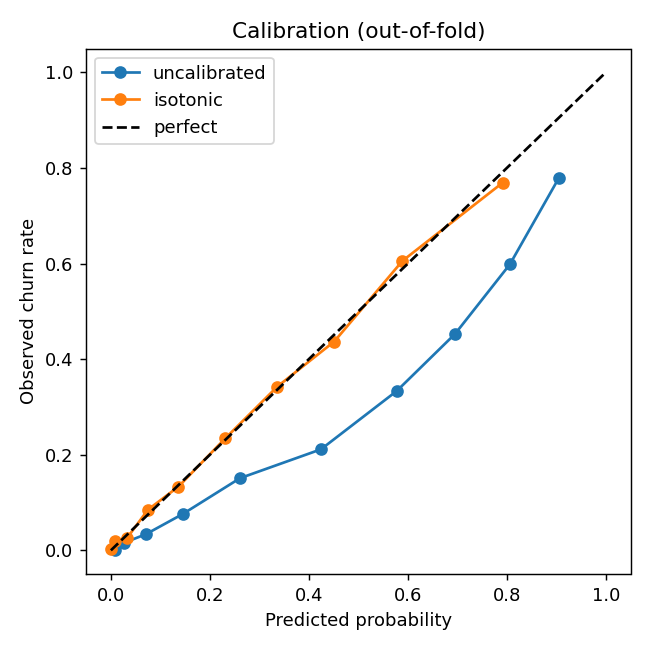

In [6]:
cal = pd.read_csv(REPORTS / "calibration_comparison.csv")
display(cal.round(4))
display(Image(filename=str(REPORTS / "calibration.png"), width=380))

**What the table says.** Both calibrators improve the Brier score sharply (0.1534 to about 0.129). Isotonic has the lowest Brier score (0.1291, selected by that rule) but sigmoid is better on log loss (0.4008 vs 0.4190), and the two Brier scores differ by only 0.0007. Isotonic regression produces step-shaped probabilities, including very confident values near 0 or 1, which log loss penalises when they are wrong. Sigmoid would be a defensible alternative; the threshold, rankings and PR-AUC are almost unaffected by the choice. This is documented as a limitation rather than hidden.

## 5. Cost-based decision threshold
The default 0.50 cut-off ignores costs. With the (illustrative, configurable) assumptions below, an offer has positive expected value only when

`P(churn) x offer success x cost of losing a customer > offer cost`, i.e. above the break-even probability of 20 / (0.30 x 200) = 33.3%.

The threshold was then picked on a 0.01 grid by minimising expected total cost on the **out-of-fold training predictions**, and frozen before the test set was scored.

In [7]:
print("Cost assumptions:", meta["costs"])
print(f"Break-even probability: {business.break_even(meta['costs']):.3f}   |   selected threshold: {meta['threshold']:.2f}")
curve = pd.read_csv(REPORTS / "threshold_curve.csv")
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(curve.threshold, curve.expected_cost)
ax.axvline(meta["threshold"], color="red", ls="--", label=f"selected {meta['threshold']:.2f}")
ax.axvline(0.5, color="gray", ls=":", label="0.50 default")
ax.set_xlabel("Decision threshold"); ax.set_ylabel("Expected cost ($, training OOF)"); ax.legend(); ax.set_title("Cost vs threshold")
plt.tight_layout(); plt.show()
print("Validation policies (training OOF):"); display(pd.read_csv(REPORTS / "policy_comparison_validation.csv"))

Cost assumptions: {'loss_cost': 200.0, 'offer_cost': 20.0, 'offer_success': 0.3}
Break-even probability: 0.333   |   selected threshold: 0.32
Validation policies (training OOF):


,policy,customers_contacted,expected_cost,saving_vs_no_offer
0,Model @ 0.32,2076,270680.0,28320.0
1,Model @ 0.50,1206,273980.0,25020.0
2,Contact everyone,5634,321980.0,-22980.0
3,No offers,0,299000.0,0.0


The cost curve is flat near its minimum, so the exact value (0.32 here) matters less than being below 0.50: the model is worth using mainly because contacting everyone costs more than doing nothing under these assumptions.

## 6. One-time evaluation on the held-out test set
The test split (20%, stratified, seed 42) is scored once, with the model and threshold that were already frozen.

In [8]:
test_sel, test_050 = meta["test_at_selected_threshold"], meta["test_at_0.50"]
if FULL:
    from sklearn.model_selection import train_test_split
    _, Xte, _, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
    model = joblib.load(MODELS / "model.joblib")
    p_test = model.predict_proba(Xte)[:, 1]
    live = metrics_at(yte, p_test, meta["threshold"])
    print(f"Recomputed from saved model: PR-AUC {live['PR-AUC']:.4f} | saved run (README, reports, metadata): {test_sel['PR-AUC']:.4f}")
    print("A gap below 0.001 can appear between machines (XGBoost/NumPy builds); the check below allows 0.001.")
    assert abs(live["PR-AUC"] - test_sel["PR-AUC"]) < 1e-3, "saved model and metadata disagree"
else:
    print("Full data not available: showing the saved test results from models/metadata.json")
rows = {f"@ {meta['threshold']:.2f} (selected)": test_sel, "@ 0.50": test_050}
display(pd.DataFrame(rows).T[["PR-AUC", "ROC-AUC", "Precision", "Recall", "F1", "TN", "FP", "FN", "TP"]].round(4))
print("Policy comparison on the test set (estimates under the cost assumptions):")
display(pd.read_csv(REPORTS / "policy_comparison_test.csv"))

Recomputed from saved model: PR-AUC 0.6721 | saved run (README, reports, metadata): 0.6724
A gap below 0.001 can appear between machines (XGBoost/NumPy builds); the check below allows 0.001.


,PR-AUC,ROC-AUC,Precision,Recall,F1,TN,FP,FN,TP
@ 0.32 (selected),0.6724,0.8538,0.5458,0.7487,0.6313,802.0,233.0,94.0,280.0
@ 0.50,0.6724,0.8538,0.6817,0.5267,0.5943,943.0,92.0,177.0,197.0


Policy comparison on the test set (estimates under the cost assumptions):


,policy,customers_contacted,expected_cost,saving_vs_no_offer
0,Model @ 0.32,513,68260.0,6540.0
1,Model @ 0.50,289,68760.0,6040.0
2,Contact everyone,1409,80540.0,-5740.0
3,No offers,0,74800.0,0.0


The saving over the 0.50 default is small (about $500 on 1,409 customers) and the whole benefit rests on the assumed 30% offer success rate, so these are *estimates under assumptions*, not proven revenue.

## 7. SHAP explanations
`ChurnExplainer` runs `shap.TreeExplainer` on the fitted (uncalibrated) XGBoost pipeline and **sums the one-hot columns back to their original feature**, so a reason reads "Contract: Month-to-month (raises churn risk)" rather than listing `Contract_Month-to-month` and `Contract_Two year` separately. SHAP explains the raw model score; the app displays the calibrated probability. The two move in the same direction but are not on the same scale.

Mean |SHAP| by original feature (300-row sample; the full-data ranking is in reports/shap_importance.csv):


,mean_abs_shap
Contract,0.741
Dependents,0.602
Tenure Months,0.485
Monthly Charges,0.222
Internet Service,0.220
Online Security,0.212
Total Charges,0.204
Payment Method,0.196


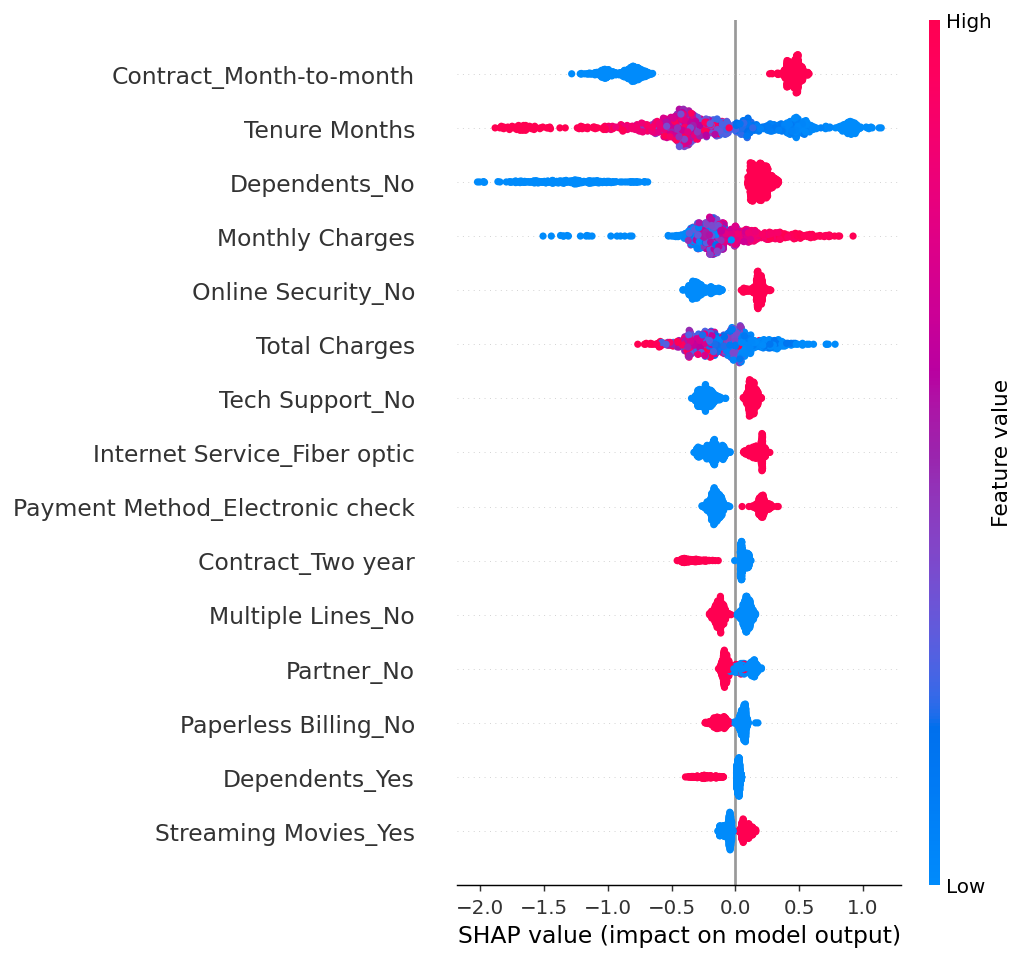

In [9]:
base = joblib.load(MODELS / "explainer_pipeline.joblib")
explainer = ChurnExplainer(base, pd.read_csv(MODELS / "background.csv"))
sample = pd.read_csv(ROOT / "data" / "sample_telco.csv")
Xs_ = validate_input(sample)
imp = explainer.global_importance(Xs_)
print("Mean |SHAP| by original feature (300-row sample; the full-data ranking is in reports/shap_importance.csv):")
display(imp.head(8).round(3).to_frame("mean_abs_shap"))
display(Image(filename=str(REPORTS / "shap_summary.png"), width=600))

In [10]:
final = joblib.load(MODELS / "model.joblib")
prob = final.predict_proba(Xs_)[:, 1]
hi, lo = int(np.argmax(prob)), int(np.argmin(prob))
reasons = explainer.top_reasons(Xs_.iloc[[hi, lo]])
for name, i, r in [("Highest risk", hi, reasons[0]), ("Lowest risk", lo, reasons[1])]:
    print(f"{name}: {prob[i]:.1%} churn probability")
    for k, line in enumerate(r, 1): print(f"   {k}. {line}")

Highest risk: 99.6% churn probability
   1. Tenure Months: 1 month (raises churn risk)
   2. Contract: Month-to-month (raises churn risk)
   3. Total Charges: $91.30 (raises churn risk)
Lowest risk: 0.0% churn probability
   1. Contract: Two year (lowers churn risk)
   2. Dependents: Yes (lowers churn risk)
   3. Tenure Months: 44 months (lowers churn risk)


## 8. Per-customer value view (extension)
The decision threshold uses one flat cost of losing a customer. To help *prioritise* offers, `business.score_customers` also estimates the **value at stake** (monthly bill x 12 months, an assumption set in `business.VALUE_HORIZON_MONTHS`) and the **expected value of an offer** = P(churn) x 0.30 x value at stake - offer cost. Customers recommended for an offer are ranked by that value, so two equally risky customers are ordered by how much revenue is at risk. This is a ranking aid only: the offer decision still follows the cost-based threshold.

In [11]:
scored = business.score_customers(Xs_, prob, explainer.top_reasons(Xs_), meta["threshold"], meta["costs"])
cols = ["Churn Probability", "Risk Category", "Recommended Action", "Value at Stake ($)", "Expected Offer Value ($)", "Offer Priority"]
print(f"{(scored['Recommended Action'] == 'Offer retention').sum()} of {len(scored)} sample customers are recommended for an offer. Top 10 by priority:")
display(scored.dropna(subset=["Offer Priority"]).sort_values("Offer Priority")[cols].head(10))

107 of 300 sample customers are recommended for an offer. Top 10 by priority:


,Churn Probability,Risk Category,Recommended Action,Value at Stake ($),Expected Offer Value ($),Offer Priority
94,0.9957,High,Offer retention,1152.0,324.10,1
126,0.9423,High,Offer retention,1209.0,321.76,2
258,0.9423,High,Offer retention,1177.2,312.77,3
18,0.9957,High,Offer retention,1095.6,307.25,4
14,0.7822,High,Offer retention,1282.8,281.03,5
204,0.9261,High,Offer retention,1071.0,277.57,6
15,0.9156,High,Offer retention,1015.8,259.02,7
68,0.7745,High,Offer retention,1154.4,248.23,8
101,0.7102,High,Offer retention,1241.4,244.50,9
72,0.6891,High,Offer retention,1249.8,238.36,10


## 9. Summary and limitations
- **Model:** XGBoost with class weights, isotonic-calibrated; chosen by out-of-fold PR-AUC on the training split, narrowly ahead of Random Forest and Logistic Regression.
- **Test set (1,409 customers, scored once):** PR-AUC 0.6724, ROC-AUC 0.8538. At the cost-based threshold of 0.32: precision 0.546, recall 0.749, F1 0.631.
- **Imbalance:** SMOTE (inside the CV pipeline) did not beat class weights, so class weights were kept.
- **Limitations:** cost figures are assumptions; one snapshot with no time-based validation; one test split carries sampling noise; SHAP reasons are associations, not causes; SMOTE ran on one-hot columns; isotonic calibration is slightly worse than sigmoid on log loss.